# 04 – Statistical Analysis

## Project: HotelIQ – Hotel Booking Analytics & Cancellation Intelligence

### Objective
The objective of this notebook is to perform statistical hypothesis testing
to validate relationships and patterns identified during Exploratory Data
Analysis (EDA).

### Statistical Techniques
- Chi-Square Test of Independence
- Mann-Whitney U Test
- Cramér's V (Effect Size)
- Rank-Biserial Correlation (Effect Size)

### Significance Level
- Alpha (α) = 0.05

### Dataset
Processed hotel booking dataset:
`data/hotel_bookings_cleaned.csv`

### Important Note
Statistical significance does not necessarily imply practical or
business significance.

In [52]:
#Importing libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, mannwhitneyu

In [53]:
# Loading the Processed Dataset
df = pd.read_csv("../data/hotel_bookings_cleaned.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (87395, 31)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,3,No Deposit,-1.0,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,4,No Deposit,-1.0,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,0,No Deposit,-1.0,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,0,No Deposit,304.0,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,0,No Deposit,240.0,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 87395 entries, 0 to 87394
Data columns (total 31 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           87395 non-null  str    
 1   is_canceled                     87395 non-null  int64  
 2   lead_time                       87395 non-null  int64  
 3   arrival_date_year               87395 non-null  int64  
 4   arrival_date_month              87395 non-null  str    
 5   arrival_date_week_number        87395 non-null  int64  
 6   arrival_date_day_of_month       87395 non-null  int64  
 7   stays_in_weekend_nights         87395 non-null  int64  
 8   stays_in_week_nights            87395 non-null  int64  
 9   adults                          87395 non-null  int64  
 10  children                        87395 non-null  float64
 11  babies                          87395 non-null  int64  
 12  meal                            87395 non-n

In [54]:
#Defining significance level
alpha = 0.05
print("Significance Level: ",alpha)

Significance Level:  0.05


In [55]:
#Bonferroni Correction for Multiple Testing
num_tests = 4

adjusted_alpha =alpha/num_tests

print("Originnal Alpha: ",alpha)
print("Bonferroni Adjusted Alpha: ", adjusted_alpha)

Originnal Alpha:  0.05
Bonferroni Adjusted Alpha:  0.0125


### 	Hotel Type vs Booking Cancellation – Chi-Square Test
Is hotel type associated with booking cancellations?

We will use Chi-Square Test

Hypotheses
- *Null Hypothesis (H0)*: Hotel type and booking cancellation are independent of each other.
- *Alternative Hypothesis (H1)*: Hotel type and booking cancellation are associated with each other.

In [ ]:
# create contingency table to examine the relationship
# between hotel type and booking cancellation.
contingency_table = pd.crosstab(df['hotel'], df['is_canceled'])

contingency_table

is_canceled,0,1
hotel,,
City Hotel,37379,16049
Resort Hotel,25991,7976


Text(0.5, 1.0, 'Hotel Type Vs Booking Cancellation')

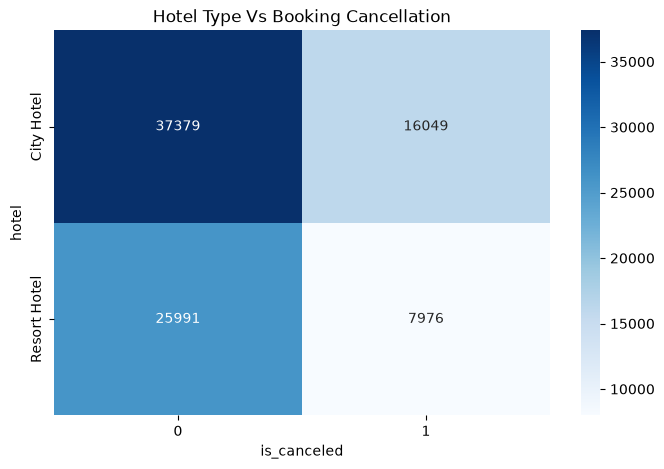

In [ ]:
# Visualization- of Hotel type Vs Cancellation
plt.figure(figsize=(8,5))

sns.heatmap(contingency_table, annot=True,fmt='d', cmap='Blues')

plt.title("Hotel Type Vs Booking Cancellation")

In [ ]:
# Contingency Table 
chi2, p_value, dof, expected = chi2_contingency(contingency_table, correction=True)

print("Chi-Square Statistaics: ",chi2)
print("P-value: ",p_value)
print("Degrees of Freesom:", dof)

Chi-Square Statistaics:  447.55793277096575
P-value:  2.4523370601952937e-99
Degrees of Freesom: 1


In [ ]:
#Interpretation
if p_value < adjusted_alpha:
    print("Reject the null hypothesis")
    print("Hotel type is significantly associated with booking cancellation.")
else:
    print("Fail to reject the Null Hypothesis")
    print("Insufficient evidence of an association between hotel and booking cancellation.")

Reject the null hypothesis
Hotel type is significantly associated with booking cancellation.


In [24]:
#Cramer's V - Cramér's V measures the strength of association between two categorical variables.
n = contingency_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * min(contingency_table.shape[0] - 1,
                    contingency_table.shape[1] - 1))
)

print("Cramér's V:", cramers_v)

Cramér's V: 0.07156181324445708


### Interpretation

- The p-value (2.45 × 10⁻⁹⁹) is significantly below the adjusted significance level of 0.0125.
- Therefore, we reject the null hypothesis.
- There is a statistically significant association between hotel type and booking cancellation.
- However, Cramér's V is approximately 0.072, indicating that the strength of this association is weak.

### Business Insight

Hotel type is associated with cancellation behaviour, but the relationship is relatively weak. Other factors should also be investigated to understand booking cancellations.


### Lead Time vs Booking Cancellation – Mann-Whitney U Test
Does lead time differ between canceled and non-canceled bookings?

Hypotheses
- *Null Hypothesis (H0)*: Lead time distributions are the same for canceled and non-canceled bookings.
- *Alternative Hypothesis (H1)*: Lead time distributions differ between the two groups.

We use Mann-Whitney U because lead time is typically skewed, making a non-parametric test appropriate.

In [ ]:
# finding Cancelled, Non cancelled bookings
cancelled = df[df['is_canceled'] == 1]['lead_time']

not_cancelled = df[df['is_canceled'] == 0]['lead_time']

print("Cancelled Bookings:", len(cancelled))
print("Non-Cancelled Bookings:", len(not_cancelled))

Cancelled Bookings: 24025
Non-Cancelled Bookings: 63370


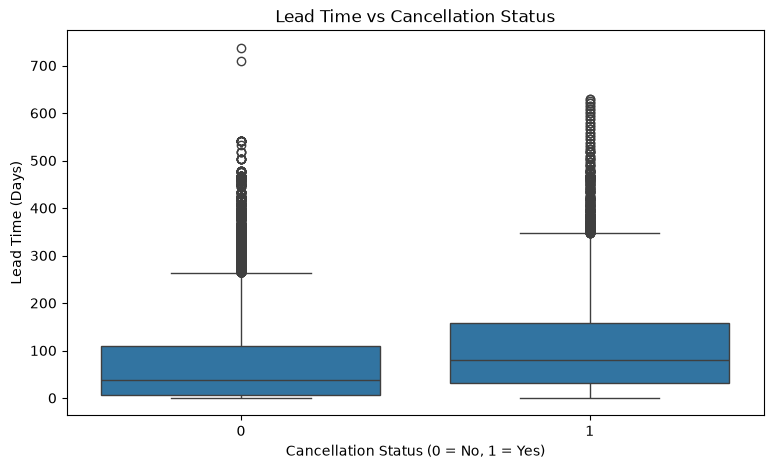

In [ ]:
# Visuzlization- Lead time vs cancellation status
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x='is_canceled', y='lead_time')

plt.title('Lead Time vs Cancellation Status')
plt.xlabel('Cancellation Status (0 = No, 1 = Yes)')
plt.ylabel('Lead Time (Days)')

plt.show()

In [ ]:
# Perform test
u_stat, p_value = mannwhitneyu(cancelled,not_cancelled,alternative='two-sided')

print("U Statistic:", u_stat)
print("P-value:", p_value)

U Statistic: 984012430.0
P-value: 0.0


In [ ]:
# Interpretation
if p_value < adjusted_alpha:
    print("Reject the Null Hypothesis.")
    print("Lead time distributions differ significantly.")
else:
    print("Fail to Reject the Null Hypothesis.")

Reject the Null Hypothesis.
Lead time distributions differ significantly.


In [ ]:
#effect size
n1 = len(cancelled)
n2 = len(not_cancelled)

rank_biserial = (2 * u_stat / (n1 * n2)) - 1

print("Rank-Biserial Correlation:", rank_biserial)

Rank-Biserial Correlation: 0.29265751888755354


### Interpretation

- The Mann-Whitney U test produced an extremely small p-value, displayed as 0.0 due to floating-point underflow.
- This value is below the adjusted significance level of 0.0125.
- Therefore, we reject the null hypothesis.
- There is statistically significant evidence that lead-time distributions differ between canceled and non-canceled bookings.
- The Rank-Biserial Correlation of approximately 0.293 indicates a meaningful difference between the two groups.

### Business Insight

Lead time is an important factor associated with booking cancellation behaviour. Hotels should pay particular attention to reservations made well in advance, as these bookings may have different cancellation patterns.

### ADR vs Hotel Type – Mann-Whitney U Test
Does ADR differ between City Hotels and Resort Hotels?

We will use Mann-Whitney U Test

Hypotheses
- *Null Hypothesis (H0)*: ADR distributions are the same for City Hotels and Resort Hotels.
- *Alternative Hypothesis (H1)*: ADR distributions differ between the two hotel types.

In [ ]:

city_adr = df[df['hotel'] == 'City Hotel']['adr']

resort_adr = df[df['hotel'] == 'Resort Hotel']['adr']

print("City Hotel Average ADR:", city_adr.mean())
print("Resort Hotel Average ADR:", resort_adr.mean())

City Hotel Average ADR: 110.98594426143598
Resort Hotel Average ADR: 99.02844937733683


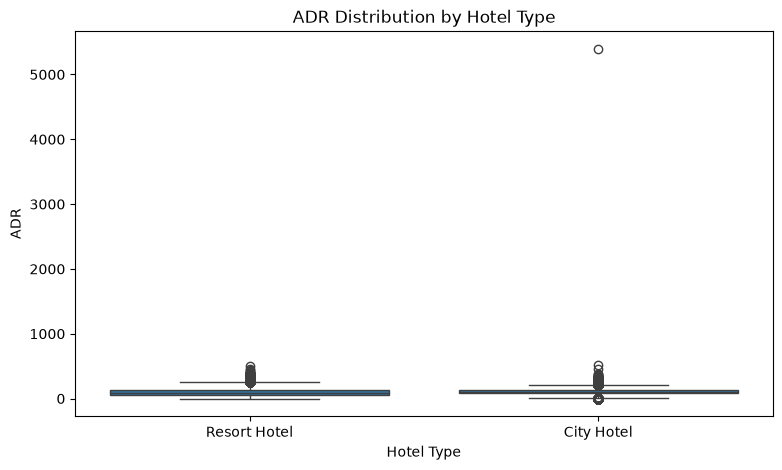

In [ ]:
#visualization
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x='hotel', y='adr')

plt.title('ADR Distribution by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('ADR')

plt.show()

In [ ]:

# Perform test
u_stat, p_value = mannwhitneyu(city_adr, resort_adr, alternative='two-sided')

print("U Statistic:", u_stat)
print("P-value:", p_value)

U Statistic: 1136599515.0
P-value: 0.0


In [ ]:
#Interprtation
if p_value < adjusted_alpha:
    print("Reject the Null Hypothesis.")
    print("ADR distributions differ significantly between hotel types.")
else:
    print("Fail to Reject the Null Hypothesis.")

Reject the Null Hypothesis.
ADR distributions differ significantly between hotel types.


In [ ]:
#effect size
n1 = len(city_adr)
n2 = len(resort_adr)

rank_biserial = (2 * u_stat / (n1 * n2)) - 1

print("Rank-Biserial Correlation:", rank_biserial)

Rank-Biserial Correlation: 0.25259696048522606


### Interpretation

- The Mann-Whitney U test produced an extremely small p-value, indicating a statistically significant difference between the ADR distributions of City Hotels and Resort Hotels.
- The p-value is below the adjusted significance level of 0.0125.
- Therefore, we reject the null hypothesis.
- City Hotels have a higher average ADR (110.99) compared to Resort Hotels (99.03).
- The Rank-Biserial Correlation of approximately 0.253 indicates a difference in the ADR distributions, with City Hotel values tending to be higher.

### Business Insight

City Hotels generally have higher room pricing than Resort Hotels in this dataset. This difference may reflect variations in location, customer demand, and pricing strategies.

### Market Segment vs Booking Cancellation – Chi-Square Tes
Is market segment associated with booking cancellations?

We will use Chi-Square Test

Hypotheses

- *Null Hypothesis (H0)*: Market segment and booking cancellation are independent.
- *Alternative Hypothesis (H1)*: Market segment and booking cancellation are associated.

In [ ]:
# create contingency table to examine the relationship
# between Market segment and booking cancellation.
contingency_market = pd.crosstab(
    df['market_segment'],
    df['is_canceled']
)

contingency_market

is_canceled,0,1
market_segment,,
Aviation,182,45
Complementary,614,88
Corporate,3702,510
Direct,10067,1737
Groups,3606,1335
Offline TA/TO,11826,2063
Online TA,33373,18245
Undefined,0,2


In [45]:
segment_counts = df['market_segment'].value_counts()

rare_segments = segment_counts[segment_counts < 5].index

df['market_segment_grouped'] = df['market_segment'].replace(
    rare_segments,
    'Other'
)

contingency_market = pd.crosstab(
    df['market_segment_grouped'],
    df['is_canceled']
)



In [46]:
# Exclude the Undefined category due to its extremely small sample size

df_market = df[df['market_segment'] != 'Undefined'].copy()

contingency_market = pd.crosstab(
    df_market['market_segment'],
    df_market['is_canceled']
)

contingency_market

is_canceled,0,1
market_segment,,
Aviation,182,45
Complementary,614,88
Corporate,3702,510
Direct,10067,1737
Groups,3606,1335
Offline TA/TO,11826,2063
Online TA,33373,18245


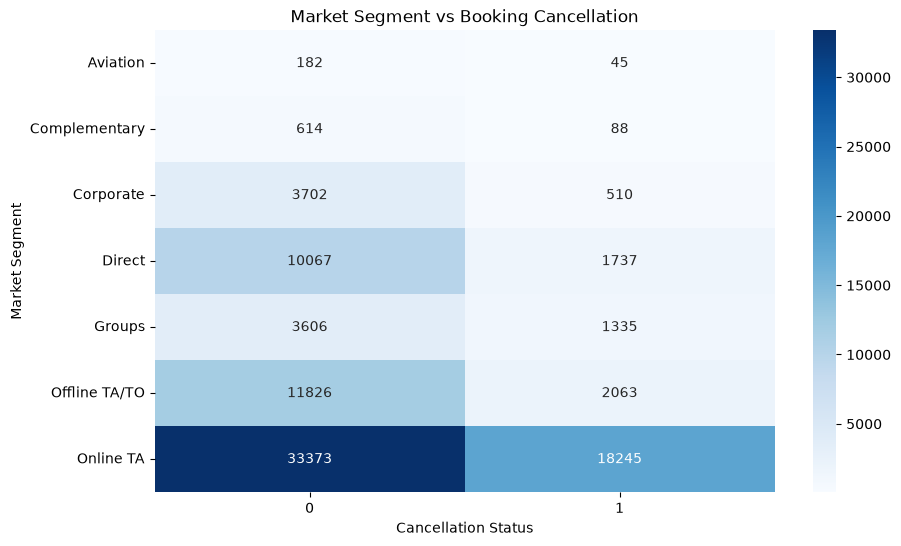

In [48]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    contingency_market,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Market Segment vs Booking Cancellation')
plt.xlabel('Cancellation Status')
plt.ylabel('Market Segment')

plt.show()

In [ ]:
# Performing Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_market,
    correction=False
)

print("Chi-Square Statistic:", chi2)
print("P-value:", p_value)
print("Degrees of Freedom:", dof)

print("\nMinimum Expected Frequency:", expected.min())
print("Percentage of Expected Frequencies Below 5:",
      (expected < 5).mean() * 100)

Chi-Square Statistic: 4263.411986730592
P-value: 0.0
Degrees of Freedom: 6

Minimum Expected Frequency: 62.398830569954114
Percentage of Expected Frequencies Below 5: 0.0


In [ ]:
# Interpretation
if p_value < adjusted_alpha:
    print("Reject the Null Hypothesis.")
    print("Market segment is significantly associated with cancellations.")
else:
    print("Fail to Reject the Null Hypothesis.")

Reject the Null Hypothesis.
Market segment is significantly associated with cancellations.


In [ ]:
#Cramer's V - Cramér's V measures the strength of association between two categorical variables.
n = contingency_market.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * min(contingency_market.shape[0] - 1,
                    contingency_market.shape[1] - 1))
)

print("Cramér's V:", cramers_v)

Cramér's V: 0.22087182873478084


### Interpretation

- The Chi-Square test produced an extremely small p-value, displayed as 0.0 due to floating-point underflow.
- Since the p-value is below the adjusted significance level of 0.0125, we reject the null hypothesis.
- There is a statistically significant association between market segment and booking cancellation.
- Cramér's V of approximately 0.22 indicates a moderate association between these variables.

### Business Insight

Cancellation behaviour varies across market segments. Understanding these differences can help hotels identify booking channels that may require closer monitoring and better cancellation management strategies.

# Overall Statistical Analysis Summary

## Key Findings

1. **Hotel Type and Cancellation:** A statistically significant association was identified between hotel type and booking cancellation. However, the effect size indicates a weak relationship.

2. **Lead Time and Cancellation:** Lead-time distributions differ significantly between canceled and non-canceled bookings. The effect size indicates a noticeable difference between the groups.

3. **ADR and Hotel Type:** ADR distributions differ significantly between City Hotels and Resort Hotels. City Hotels have a higher average ADR in the dataset.

4. **Market Segment and Cancellation:** The statistical test indicates an association between market segment and booking cancellation. The effect size helps quantify the strength of this relationship.

## Conclusion

Statistical hypothesis testing helped validate several patterns observed during exploratory data analysis.

The results indicate that hotel type, lead time, ADR, and market segment have statistically significant relationships with selected booking outcomes or characteristics.

However, statistical significance does not establish causation. Effect sizes are also important when evaluating the practical importance of these relationships.

These findings provide a foundation for further business analysis and machine learning-based booking cancellation prediction.